<a href="https://colab.research.google.com/github/Juan-Zuar76/Invernadero-inteligente-/blob/main/invernadero_Analisis_Historico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
from google.colab import drive
drive.mount('/content/drive')

datos = pd.read_csv(
    '/content/drive/MyDrive/Mecatronica/Invernadero.csv'
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Inicio:

En esta sección se presenta el proyecto y el objetivo del análisis histórico de las variables ambientales registradas por el NodeMCU ESP8266 y almacenadas en ThingSpeak.


In [2]:
import pandas as pd

# Cargar el archivo CSV
datos = pd.read_csv('/content/Invernadero.csv')

# Mostrar los primeros registros
datos.head()

,created_at,entry_id,field1,field2,field3,field4,field5,latitude,longitude,elevation,status
0,2026-10-28T03:33:58+00:00,1,22.0,61.0,58,100,658,NaN,NaN,NaN,NaN
1,2026-10-28T03:34:17+00:00,2,22.0,62.0,58,100,655,NaN,NaN,NaN,NaN
2,2026-10-28T03:34:37+00:00,3,22.0,62.0,58,100,660,NaN,NaN,NaN,NaN
3,2026-10-28T03:34:57+00:00,4,22.0,62.0,56,100,668,NaN,NaN,NaN,NaN
4,2026-10-28T03:35:17+00:00,5,22.0,62.0,55,100,673,NaN,NaN,NaN,NaN


Carga de datos:

Se importa el archivo CSV descargado desde ThingSpeak para trabajar con las mediciones históricas del invernadero.

In [4]:
# Información general del conjunto de datos
datos.info()

# Cantidad de filas y columnas
print("Dimensiones:", datos.shape)

# Nombres de las columnas
print("Columnas:", datos.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3137 entries, 0 to 3136
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   created_at  3137 non-null   object 
 1   entry_id    3137 non-null   int64  
 2   field1      3137 non-null   float64
 3   field2      3137 non-null   float64
 4   field3      3137 non-null   int64  
 5   field4      3137 non-null   int64  
 6   field5      3137 non-null   int64  
 7   latitude    0 non-null      float64
 8   longitude   0 non-null      float64
 9   elevation   0 non-null      float64
 10  status      0 non-null      float64
dtypes: float64(6), int64(4), object(1)
memory usage: 269.7+ KB
Dimensiones: (3137, 11)
Columnas: ['created_at', 'entry_id', 'field1', 'field2', 'field3', 'field4', 'field5', 'latitude', 'longitude', 'elevation', 'status']


Preparación y limpieza

Se revisa la estructura de los datos, se convierten las fechas y se eliminan las columnas que no intervienen en el análisis.

In [23]:
datos['created_at'] = pd.to_datetime(datos['created_at'])

datos = datos.drop(columns=[
    'latitude', 'longitude', 'elevation', 'status'
])

datos = datos.rename(columns={
    'created_at': 'Fecha',
    'entry_id': 'Registro',
    'field1': 'Temperatura',
    'field2': 'Humedad_Ambiente',
    'field3': 'Humedad_Suelo',
    'field4': 'Iluminacion',
    'field5': 'ADC_Suelo'
})

datos.head()

,Fecha,Registro,Temperatura,Humedad_Ambiente,Humedad_Suelo,Iluminacion,ADC_Suelo
0,2026-10-28 03:33:58+00:00,1,22.0,61.0,58,100,658
1,2026-10-28 03:34:17+00:00,2,22.0,62.0,58,100,655
2,2026-10-28 03:34:37+00:00,3,22.0,62.0,58,100,660
3,2026-10-28 03:34:57+00:00,4,22.0,62.0,56,100,668
4,2026-10-28 03:35:17+00:00,5,22.0,62.0,55,100,673


Análisis estadístico

Se calculan promedios, medianas, máximos, mínimos y desviaciones estándar.

In [6]:
# Estadísticas descriptivas de los sensores
estadisticas = datos[
    ['Temperatura', 'Humedad_Ambiente',
     'Humedad_Suelo', 'Iluminacion', 'ADC_Suelo']
].describe()

estadisticas

,Temperatura,Humedad_Ambiente,Humedad_Suelo,Iluminacion,ADC_Suelo
count,3137.000000,3137.000000,3137.000000,3137.000000,3137.000000
mean,21.332483,52.920306,75.682180,98.469876,544.965891
std,1.552670,11.276472,6.427335,12.276775,40.619640
min,18.000000,28.000000,0.000000,0.000000,399.000000
25%,21.000000,44.000000,71.000000,100.000000,517.000000
50%,21.000000,50.000000,76.000000,100.000000,544.000000
75%,22.000000,60.000000,80.000000,100.000000,572.000000
max,43.000000,89.000000,99.000000,100.000000,1024.000000


Visualización gráfica

Se representan las variaciones de temperatura, humedad ambiente, humedad del suelo e iluminación.

En la imagen siguiente se observa un pico de 43 grados , se dio en el marco de un experimento de variacion de temperatura aplicando calor con un secador de cabellos , el resultado fue increible.

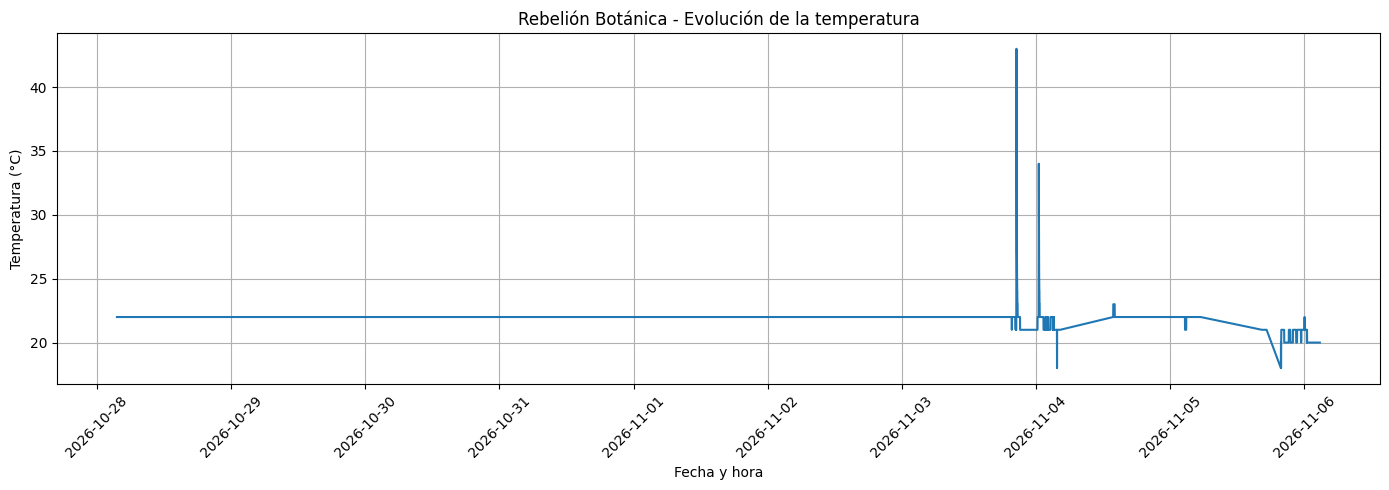

In [7]:
import matplotlib.pyplot as plt

# Convertir la fecha a formato de tiempo
datos['Fecha'] = pd.to_datetime(datos['Fecha'])

# Gráfico histórico de temperatura
plt.figure(figsize=(14, 5))

plt.plot(datos['Fecha'], datos['Temperatura'])

plt.title('Rebelión Botánica - Evolución de la temperatura')
plt.xlabel('Fecha y hora')
plt.ylabel('Temperatura (°C)')
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

 Evolución histórica de la humedad ambiente

El gráfico representa las variaciones de humedad relativa del aire registradas por el sensor DHT11 durante el período de funcionamiento del invernadero.

Se observa que la humedad presentó fluctuaciones importantes, alcanzando un valor máximo cercano al 89 % y descendiendo hasta aproximadamente el 28 %.

Estas variaciones se relacionan con los cambios de temperatura y las pruebas de funcionamiento de los actuadores. La ventilación y la evaporación del agua aportada por la bomba pueden modificar las condiciones ambientales internas.

Los resultados permiten observar el comportamiento del ambiente y evaluar la respuesta del sistema ante distintas condiciones de funcionamiento.

Nota: los espacios sin registros representan períodos en los que no se recibieron mediciones en ThingSpeak.

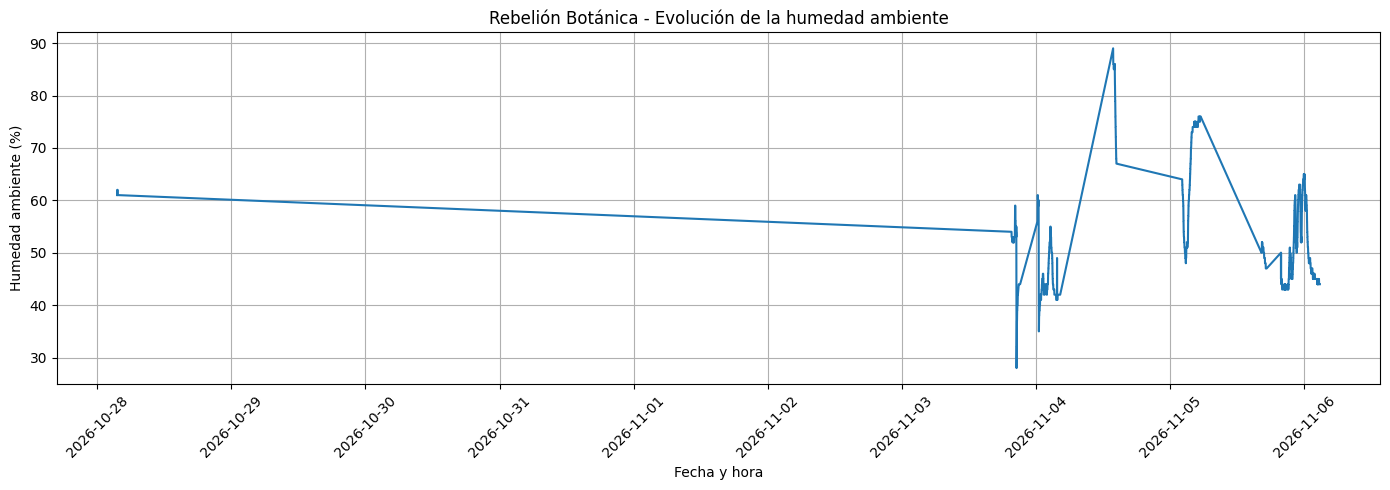

In [8]:
# Gráfico histórico de humedad ambiente

plt.figure(figsize=(14, 5))

plt.plot(datos['Fecha'], datos['Humedad_Ambiente'])

plt.title('Rebelión Botánica - Evolución de la humedad ambiente')
plt.xlabel('Fecha y hora')
plt.ylabel('Humedad ambiente (%)')

plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Evolución histórica de la humedad del suelo

En esta sección se analiza el comportamiento de la humedad del suelo mediante los registros obtenidos por el sensor FC-28.

El sensor permite detectar las variaciones de humedad en el sustrato y proporcionar información para el control automático del sistema de riego.

Los valores se expresan en porcentaje, utilizando los parámetros de calibración establecidos durante las pruebas experimentales.

El objetivo es observar cómo varía la humedad del suelo a lo largo del tiempo y evaluar su relación con el funcionamiento de la bomba de agua.

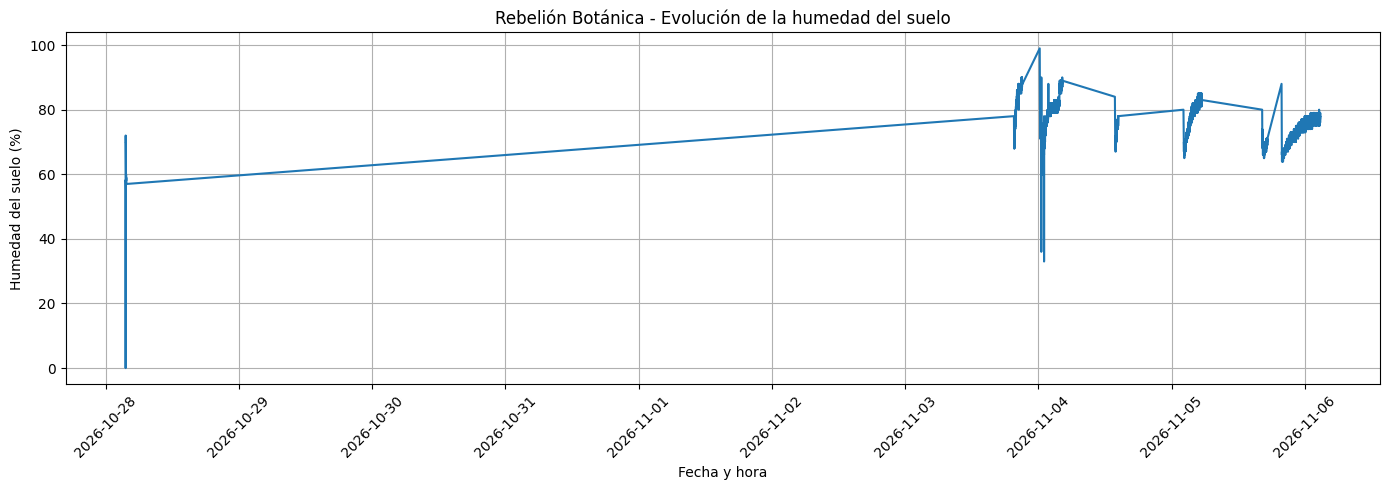

In [9]:
# Gráfico histórico de humedad del suelo

plt.figure(figsize=(14, 5))

plt.plot(datos['Fecha'], datos['Humedad_Suelo'])

plt.title('Rebelión Botánica - Evolución de la humedad del suelo')
plt.xlabel('Fecha y hora')
plt.ylabel('Humedad del suelo (%)')

plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Evolución histórica de la iluminación

En esta sección se analizan los registros del sensor digital de luz instalado en el invernadero.

El sensor trabaja mediante una salida digital que permite distinguir entre dos estados: presencia de luz y oscuridad.

Para facilitar la visualización, los estados se representan mediante valores de 100 % y 0 %, respectivamente. Estos porcentajes son una representación de los estados digitales y no una medición física de intensidad lumínica.

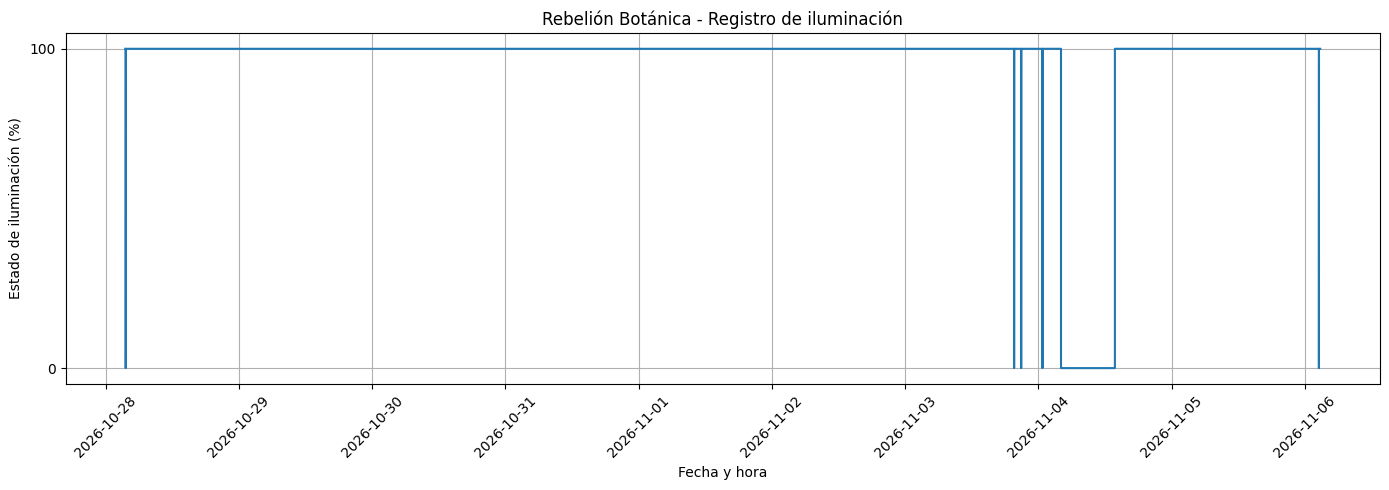

In [10]:
# Gráfico histórico de iluminación

plt.figure(figsize=(14, 5))

plt.step(datos['Fecha'], datos['Iluminacion'], where='post')

plt.title('Rebelión Botánica - Registro de iluminación')
plt.xlabel('Fecha y hora')
plt.ylabel('Estado de iluminación (%)')

plt.yticks([0, 100])
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Análisis comparativo de temperatura y humedad ambiente

En esta sección se realiza una comparación entre la temperatura y la humedad relativa del aire registradas por el sensor DHT11.

El objetivo es observar cómo se comportan ambas variables a lo largo del tiempo y reconocer posibles relaciones entre sus variaciones.

Este análisis permite estudiar los cambios ambientales producidos durante las pruebas experimentales del invernadero.

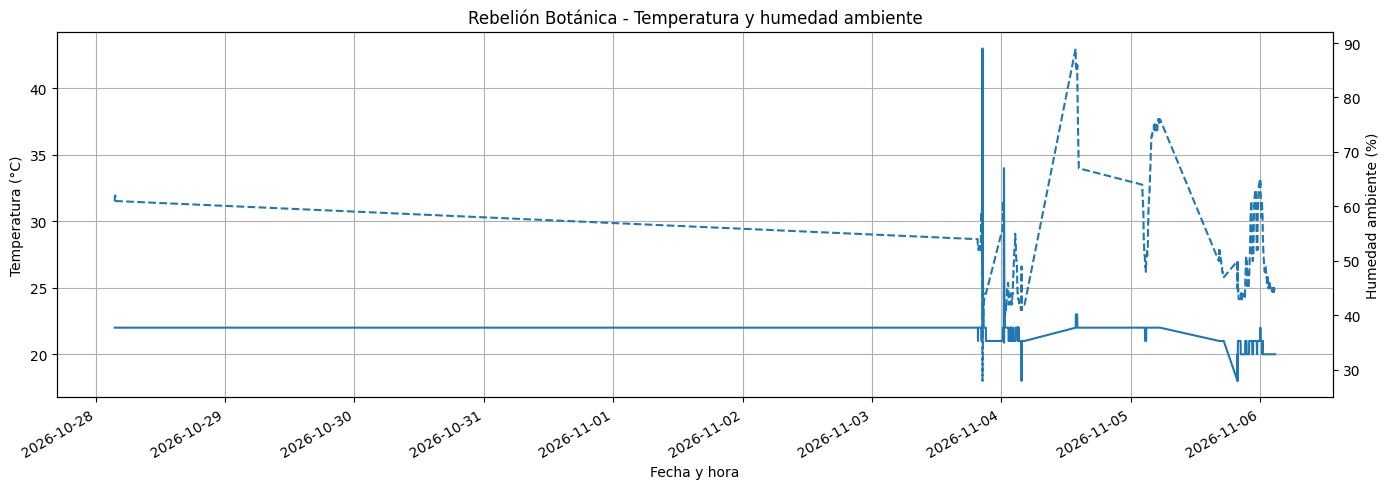

In [11]:
# Comparación de temperatura y humedad ambiente

fig, ax1 = plt.subplots(figsize=(14, 5))

ax1.plot(datos['Fecha'], datos['Temperatura'],
         label='Temperatura (°C)')

ax1.set_xlabel('Fecha y hora')
ax1.set_ylabel('Temperatura (°C)')
ax1.grid(True)

ax2 = ax1.twinx()

ax2.plot(datos['Fecha'], datos['Humedad_Ambiente'],
         label='Humedad ambiente (%)', linestyle='--')

ax2.set_ylabel('Humedad ambiente (%)')

plt.title('Rebelión Botánica - Temperatura y humedad ambiente')
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

Interpretación comparativa de temperatura y humedad ambiente

La comparación de ambas variables permite observar una relación entre las variaciones de temperatura y humedad relativa del aire.

Durante las pruebas de calentamiento, la temperatura alcanzó aproximadamente 43 °C, mientras que la humedad relativa descendió hasta valores cercanos al 28 %.

Posteriormente, durante las pruebas de funcionamiento del sistema, se registraron cambios en ambas variables, con una recuperación de la humedad ambiente.

Estos resultados permiten evaluar la respuesta del ambiente ante las variaciones térmicas y el funcionamiento de los actuadores de ventilación y riego.

Es importante considerar que la humedad relativa también depende de la temperatura, por lo que sus variaciones no pueden atribuirse exclusivamente al funcionamiento de la bomba.

In [12]:
# Correlación entre temperatura y humedad ambiente

correlacion = datos[
    ['Temperatura', 'Humedad_Ambiente']
].corr()

print("Correlación entre temperatura y humedad ambiente:")
display(correlacion)

Correlación entre temperatura y humedad ambiente:


,Temperatura,Humedad_Ambiente
Temperatura,1.0000,0.1117
Humedad_Ambiente,0.1117,1.0000


**Análisis de correlación entre temperatura y humedad ambiente**

El cálculo estadístico arrojó un coeficiente de correlación de 0,1117 entre la temperatura y la humedad relativa del aire.

Este resultado indica una relación lineal positiva muy débil al considerar la totalidad de los registros disponibles.

Sin embargo, este valor debe interpretarse teniendo en cuenta que las mediciones corresponden a distintos momentos y condiciones de funcionamiento del invernadero.

Por lo tanto, el resultado general no representa necesariamente el comportamiento observado durante cada prueba experimental.

In [13]:
# Correlación entre humedad del suelo y lectura ADC

correlacion_suelo = datos[
    ['Humedad_Suelo', 'ADC_Suelo']
].corr()

print("Correlación entre humedad del suelo y ADC:")
display(correlacion_suelo)

Correlación entre humedad del suelo y ADC:


,Humedad_Suelo,ADC_Suelo
Humedad_Suelo,1.000,-0.999
ADC_Suelo,-0.999,1.000


 **Análisis de correlación entre humedad del suelo y lectura ADC**

El cálculo estadístico arrojó un coeficiente de correlación de -0,999 entre la humedad del suelo y la lectura analógica del sensor FC-28.

Este resultado indica una relación lineal inversa extremadamente fuerte entre ambas variables.

Esto significa que, a medida que aumenta la humedad del suelo, disminuye el valor de lectura ADC. Por el contrario, cuando disminuye la humedad, aumenta la lectura analógica.

El resultado coincide con el comportamiento observado durante las pruebas de calibración realizadas en el taller y confirma la relación entre la lectura analógica y el porcentaje de humedad calculado.

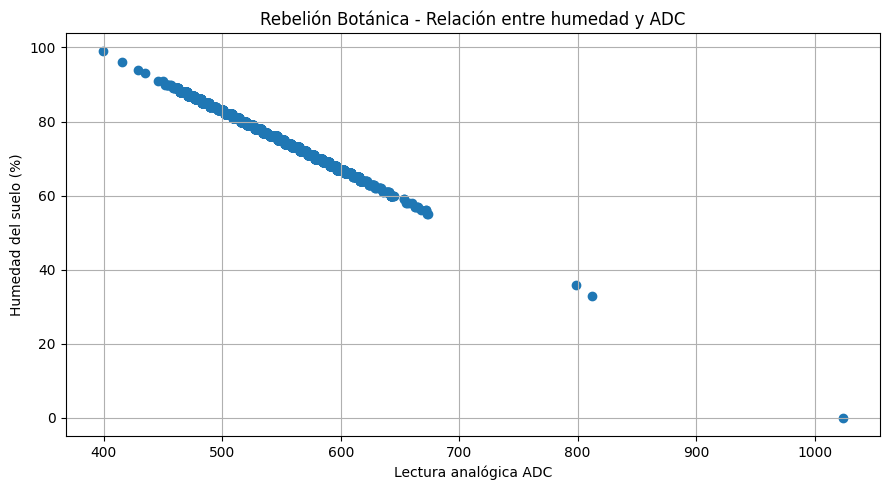

In [14]:
# Relación entre humedad del suelo y lectura ADC

plt.figure(figsize=(9, 5))

plt.scatter(datos['ADC_Suelo'], datos['Humedad_Suelo'])

plt.title('Rebelión Botánica - Relación entre humedad y ADC')
plt.xlabel('Lectura analógica ADC')
plt.ylabel('Humedad del suelo (%)')

plt.grid(True)
plt.tight_layout()
plt.show()

**Representación gráfica de la relación entre humedad del suelo y ADC**

El gráfico de dispersión muestra la relación entre las lecturas analógicas del sensor FC-28 y los porcentajes de humedad calculados.

Se observa una tendencia lineal descendente: a medida que aumenta el valor ADC, disminuye el porcentaje de humedad del suelo.

Esta relación coincide con las pruebas de calibración realizadas experimentalmente, donde se comprobó que el sensor entrega valores analógicos más bajos cuando aumenta la humedad.

El resultado permite validar el comportamiento inverso del sensor y la conversión utilizada para expresar las mediciones en porcentaje.

**Análisis de las condiciones de activación automática**

El sistema de control del invernadero establece umbrales de funcionamiento para los actuadores.

El ventilador está programado para activarse cuando la temperatura alcanza los 33 °C, mientras que la bomba de agua se activa cuando la humedad del suelo desciende por debajo del 40 %.

En esta sección se identifican los registros históricos que cumplen dichas condiciones, con el objetivo de evaluar la frecuencia con la que el sistema habría solicitado la activación de cada actuador.

In [16]:
# Identificar las condiciones de activación

temperatura_alta = datos[datos['Temperatura'] >= 33]

suelo_seco = datos[datos['Humedad_Suelo'] < 40]

print("Registros con temperatura igual o superior a 33 °C:",
      len(temperatura_alta))

print("Registros con humedad del suelo inferior al 40 %:",
      len(suelo_seco))

Registros con temperatura igual o superior a 33 °C: 16
Registros con humedad del suelo inferior al 40 %: 3


**Resultados de las condiciones de activación**

Al analizar los 3.137 registros históricos se obtuvieron los siguientes resultados:

- Se identificaron 16 mediciones con temperaturas iguales o superiores a 33 °C, condición establecida para la activación del ventilador.
- Se identificaron 3 mediciones con valores de humedad del suelo inferiores al 40 %, condición establecida para la activación de la bomba de agua.

Estos resultados permiten identificar los momentos en los que las variables ambientales alcanzaron los umbrales configurados en el sistema automático de control.

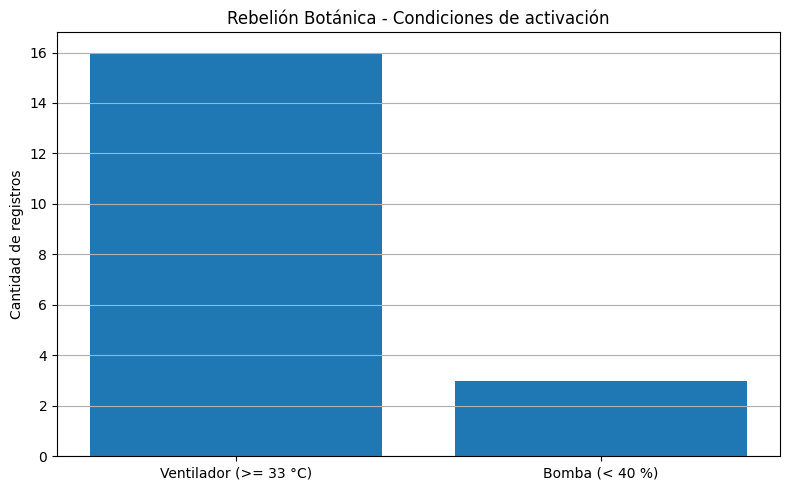

In [17]:
# Comparación de las condiciones de activación

condiciones = ['Ventilador (>= 33 °C)', 'Bomba (< 40 %)']
registros = [len(temperatura_alta), len(suelo_seco)]

plt.figure(figsize=(8, 5))
plt.bar(condiciones, registros)

plt.title('Rebelión Botánica - Condiciones de activación')
plt.ylabel('Cantidad de registros')
plt.grid(axis='y')

plt.tight_layout()
plt.show()

   **Representación gráfica de las condiciones de activación**

El gráfico permite comparar la cantidad de registros históricos que cumplieron las condiciones establecidas para el funcionamiento automático de los actuadores.

Se observa que 16 mediciones alcanzaron temperaturas iguales o superiores a 33 °C, mientras que solamente 3 mediciones registraron una humedad del suelo inferior al 40 %.

Esta comparación permite visualizar la frecuencia con la que se presentaron ambas condiciones durante el período de observación.

In [18]:
# Promedios diarios de las variables ambientales

datos['Fecha'] = pd.to_datetime(datos['Fecha'])

promedios_diarios = datos.groupby(
    datos['Fecha'].dt.date
)[['Temperatura', 'Humedad_Ambiente', 'Humedad_Suelo']].mean()

display(promedios_diarios.round(2))

,Temperatura,Humedad_Ambiente,Humedad_Suelo
Fecha,,,
2026-10-28,22.00,61.69,58.28
2026-11-03,23.07,48.49,82.97
2026-11-04,21.75,49.60,77.47
2026-11-05,21.18,56.61,73.51
2026-11-06,20.19,48.98,76.60


   **Análisis de promedios diarios**

Se calcularon los valores promedio diarios de temperatura, humedad ambiente y humedad del suelo utilizando los registros históricos almacenados en ThingSpeak.

Los resultados permiten observar la evolución de las condiciones ambientales del invernadero durante el período registrado.

Se destaca el incremento de la humedad del suelo entre el 28 de octubre y el 3 de noviembre, pasando de un promedio de 58,28 % a 82,97 %.

También se observan variaciones en la temperatura y la humedad ambiente, lo que permite estudiar el comportamiento de las variables a lo largo del tiempo.

Se aclara que las fechas sin registros no se consideran valores iguales a cero.

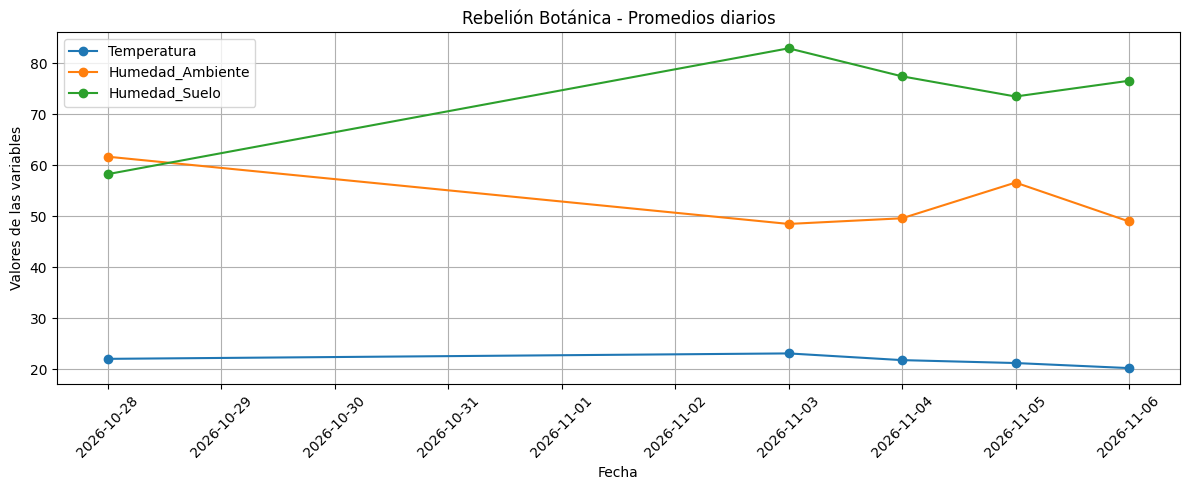

In [19]:
# Evolución diaria de las variables ambientales

promedios_diarios.plot(
    figsize=(12, 5),
    marker='o'
)

plt.title('Rebelión Botánica - Promedios diarios')
plt.xlabel('Fecha')
plt.ylabel('Valores de las variables')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

 **Interpretación de la evolución diaria de las variables**

El gráfico representa los promedios diarios de temperatura, humedad ambiente y humedad del suelo registrados por el sistema.

Se observa que la temperatura presentó variaciones moderadas durante el período analizado. La humedad ambiente mostró cambios más pronunciados, mientras que la humedad del suelo experimentó un incremento importante a partir del 3 de noviembre.

Este comportamiento permite observar la respuesta de las variables ambientales durante las pruebas realizadas con el sistema de control del invernadero.

Los resultados muestran la utilidad del registro histórico para estudiar las condiciones ambientales y evaluar el funcionamiento general del proyecto.

  **Conclusión general del análisis histórico Rebelión Botánica**

A partir de los datos registrados por el NodeMCU ESP8266 y almacenados en la plataforma ThingSpeak, se realizó un análisis histórico de las principales variables ambientales del invernadero.

Mediante Google Colab y la biblioteca Pandas se organizaron y procesaron las mediciones, obteniendo estadísticas descriptivas, gráficos de evolución, comparaciones y correlaciones entre las variables.

Los resultados permitieron comprobar el comportamiento de los sensores y observar la relación inversa entre la lectura analógica del sensor FC-28 y el porcentaje de humedad del suelo.

También se identificaron registros que alcanzaron las condiciones establecidas para la activación automática del ventilador y la bomba de agua.

Las pruebas prácticas demostraron que el sistema puede responder a los cambios ambientales mediante el accionamiento de sus actuadores. Además, el almacenamiento histórico permite consultar y estudiar las mediciones a lo largo del tiempo.

En conclusión, el proyecto **Rebelión Botánica** integra adquisición de datos, monitoreo remoto, almacenamiento histórico y control automático, demostrando la aplicación de conocimientos de electrónica, programación y análisis de datos en un sistema de invernadero inteligente.

El análisis podrá ampliarse incorporando nuevos registros y períodos de observación, permitiendo evaluar el comportamiento del sistema con mayor precisión.